In [4]:
from typing import Any
import numpy as np
from autograd import Node

### Forward

In [3]:
x = Node(data=2, label='x')
w1 = Node(data=0.1, label='w1')
b1 = Node(data=1, label='b1')

l1 = x*w1 + b1
l1.label = 'l1'
print(f"l1: {l1}")

w2 = Node(data=0.2, label='w2')
b2 = Node(data=2, label='b2')

l2 = l1*w2 + b2
l2.label = 'l2'
print(f"l2: {l2}")

# Target and loss
y = Node(data=5.0, label='y')  # example actual y labeled data value
L = l2.mse(y)  # MSE
L.label = "L"

print(f"L: {L}")

l1: Node(1.2, ops=+, label=l1)
l2: Node(2.24, ops=+, label=l2)
L: Node(7.617599999999999, ops=mse, label=L)


In [4]:
# backprop using backward()
L.grad = 1.0
L._backward()
l2._backward()

# Backpropagate through l1 * w2
mul_node = next(iter(l2.parents - {b2}))
mul_node._backward()

b2._backward()

l1._backward()

TypeError: unsupported operand type(s) for -: 'tuple' and 'set'

In [ ]:
l1.grad, l2.grad * w2.data

In [ ]:
# Manual backprop
# handle last nodes (MSE output) gradient base case
L.grad = 1.0  # dL/dL = 1

# dL/dl2
l2.grad = 2 * (l2.data - y.data)

# dL/dw2 = dL/dl2 * dl2/dw2
w2.grad = l2.grad * l1.data

# dL/db2 = dL/dl2 * dl2/db2
b2.grad = l2.grad * 1

# dL/dl1 = dL/dl2 * dl2/dl1
l1.grad = l2.grad * w2.data

# dL/dw1 = dL/dl2 * dl2/dl1 * dl1/dw1
w1.grad = l1.grad * x.data

# dL/db1 = dL/dl2 * dl2/dl1 * dl1/db1
b1.grad = l1.grad * 1

# dL/dx = dL/dl2 * dl2/dl1 * dl1/dx
x.grad = l1.grad * w1.data

In [ ]:
l1.grad, b1.grad, w1.grad, x.grad

In [ ]:
# numerical gradient check using finite differences
h = 1e-5

# Original loss (already calculated)
loss_original = L

# Separate forward pass with w1 slightly increased
x_check = Node(data=x.data)
w1_check = Node(data=w1.data + h)
b1_check = Node(data=b1.data)

l1_check = x_check * w1_check + b1_check

w2_check = Node(data=w2.data)
b2_check = Node(data=b2.data)

l2_check = l1_check * w2_check + b2_check

y_check = Node(data=y.data)

loss_check = (l2_check.data - y_check.data)**2

# Numerical derivative: rise over run
numerical_grad_w1 = (loss_check - loss_original) / h

print(f"Analytical gradient: {w1.grad}")
print(f"Numerical gradient:  {numerical_grad_w1}")

In [ ]:
from sympy import symbols
from sympy.plotting import plot

c = symbols('c')

L = (2.0 * -3.0) + c

plot(L, (c, 0, 15), show=True)

## NN

In [5]:
def print_graph(root: Node, just_grads: bool = False):

    seen = set()

    def traverse(node, depth=0, edge_label="ROOT"):

        indent = "    " * depth
        node_id = id(node)

        # Avoid printing shared nodes multiple times
        if node_id in seen:
            print(f"{indent}└── [Already visited: {node.label or node_id}]")
            return

        seen.add(node_id)

        label = node.label or "Node"

        print(
            f"{indent}└── {edge_label}: {label} "
            # f"| data={node.data:.6f} "
            f"| grad={node.grad:.6f} "
            # f"| op={node.ops or 'Leaf'}"
        )

        # Recursively traverse parents
        for i, parent in enumerate(node.parents):
            traverse(parent, depth + 1, f"Parent {i}")

    traverse(root)

In [6]:
import random

class Neuron:

    def __init__(self, n: int, weights: list | None = None, bias: float | None = None) -> None:
        self.weights = weights if weights else [Node(data=random.uniform(-1, 1)) for _ in range(n)]
        self.bias = bias if bias is not None else Node(random.uniform(-1, 1))

    def __call__(
            self, 
            X: list | np.ndarray, # previous layers neurons activation values
            activation_fn: str | None = 'relu') -> Node | Any | float:
        #TODO: convert to matric mul for optimization
        activation = sum((xi*wi for xi, wi in zip(X, self.weights)), start=self.bias)
        if activation_fn == 'relu':
            activation = activation.relu()
        return activation

    def parameters(self)-> list | list[Node]:
        return self.weights + [self.bias]

class LinearLayer:

    def __init__(self, in_features: int, out_features: int):
        self.in_features = in_features
        self.out_features = out_features
        self.construct()

    def construct(self) -> None:
        self.neurons = [Neuron(n=self.in_features) for _ in range(self.out_features)]

    def __repr__(self) -> str:
        return f"LinearLayer (in: {self.in_features}, out:{self.out_features})"

    def __call__(self, x: list | np.ndarray, act: bool = True):
        return [n(x, activation_fn=None if not act else 'relu') for n in self.neurons]

    def parameters(self):
        return [param for neuron in self.neurons for param in neuron.parameters()]

class Network:

    def __init__(self, layers: list) -> None:
        self.layers = [LinearLayer(in_features=layers[i], out_features=layers[i+1]) for i in range(len(layers) - 1)]

    def __repr__(self) -> str:
            return f"Net (Layers ({[layer for layer in self.layers]}))"

    def __call__(self, x: list | np.ndarray, no_act: set | None = None):
        for i, layer in enumerate(self.layers): 
            x = layer(x, act=False if i in no_act else True)
        return x[0] if len(x) == 1 else x

    def parameters(self)-> list[Any | Node]:
        return [param for layer in self.layers for param in layer.parameters()]

    def zero_grad(self) -> None:
        for param in self.parameters(): param.grad = 0

In [ ]:
# regression example
ys = [3.3]
net = Network(layers=[1, 2, 1])

In [ ]:
y_hats = net([2.3], no_act={1})

# MSE loss
loss = sum((y_hat - y)**2 for y_hat, y in zip(y_hats, ys))
print(f"loss: {loss}")
loss.backward()
for node in net.parameters():
    node.data -= 0.01 * node.grad

In [7]:
lr = 0.001
losses = []
# Training
for epoch in range(30):
    # Forward pass
    y_hats = net([2.3], no_act={1})

    # Calculate loss (SSE)
    # loss = sum(
    #     (y_hat - y)**2
    #     for y_hat, y in zip(y_hats, ys)
    # )
    # Calculate loss (SSE)
    loss = sum(
        (y_hat - y)**2
        for y_hat, y in zip(y_hats, ys)
    ) * (1/2*len(y_hats))
    losses.append(loss.data)
    net.zero_grad()

    # Backpropagation
    loss.backward()

    # Gradient descent
    for param in net.parameters():
        param.data -= lr * param.grad

    print(f"Epoch {epoch}: Loss = {loss.data:.6f}")

NameError: name 'net' is not defined

In [ ]:
y_hats

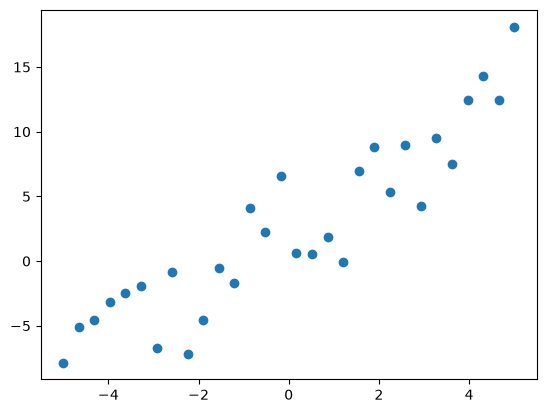

In [8]:
# Generate linear dataset
import matplotlib.pyplot as plt

X = np.linspace(-5, 5, 30)
def linear(X_axis: float) -> float: 
    return (X_axis*2.3 + 2) + random.uniform(-5, 5)

def parabola(X_axis: float) -> float:
    return (X_axis**2)# + random.uniform(-5, 5)

def quadratic_porabola(X_axis: float) -> float:
    return (X_axis**4 - 5*X_axis**2 + 4)# + random.uniform(-5, 5)

y = [linear(x_val) for x_val in X]

# pyplot.plot(X_axis, y)
plt.scatter(X, y)

In [10]:
# regression example
mass = [[x] for x in X]
epoch_predictions = []
net = Network(layers=[1, 4, 1])
lr = 0.0005
# Training
for epoch in range(100):
    # Forward pass
    y_hats = [net(x, no_act={1}) for x in mass]
    epoch_predictions.append([y_hat.data for y_hat in y_hats])
    # Calculate loss (SSE)
    # loss = sum(
    #     (y_hat - y)**2
    #     for y_hat, y in zip(y_hats, ys)
    # )
    # Calculate loss (SSE)
    #TODO: Add all operations to the value class to use this loss fn
    loss = sum(
        (y_hat - y)**2
        for y_hat, y in zip(y_hats, ys)
    ) / (2 * len(ys))

    net.zero_grad()
    # Backpropagation
    loss.backward()

    # Gradient descent
    for param in net.parameters():
        param.data -= lr * param.grad

    print(f"Epoch {epoch}: Loss = {loss.data:.6f}")

NameError: name 'ys' is not defined

In [ ]:
plt.scatter(X, y, label='Actual')
plt.scatter(X, [y_hat.data for y_hat in y_hats], color='orange', label='Predicted')

plt.legend()
plt.show()

In [ ]:
import ipywidgets as widgets
from IPython.display import display

def plot_epoch(epoch):
    plt.figure(figsize=(8, 4))
    plt.scatter(X, y)
    plt.plot(X, epoch_predictions[epoch], color="red")
    plt.title(f"Epoch: {epoch}")
    plt.show()

widgets.interact(
    plot_epoch,
    epoch=widgets.IntSlider(min=0, max=99, step=1)
);